# Notebook 7 - Encoding Categorical Variables

In this notebook I learn how to convert categorical columns into numbers that a model can use. I cover nominal, ordinal and binary variables, label encoding, ordinal encoding, one-hot encoding, dummy variables, frequency encoding, target encoding, unknown categories and high-cardinality categories. For each technique I write when to use it, and I show the risk of using the wrong one.

**Dataset:** Telco Customer Churn, after Notebooks 2 to 6.

**Important:** Many encoders learn something from the data (the list of categories, the frequencies, the target averages). So they must be fitted on the training data only. For this notebook I make a simple stratified 80/20 train/test split first. The formal split with a validation set is in Notebook 12.

**Demo data:** Telco has only low-cardinality categories (up to 4 labels), so for the high-cardinality topic I create a small labelled demo table with 200 cities. Small demo lists (education levels, noise categories) are always labelled as demo.

**Rule:** `df` (raw data) is never changed.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style("whitegrid")
pd.set_option("display.width", 200)

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")   # raw data, never modified

def fix_data_types(data):
    # Notebook 2
    out = data.copy()
    out["TotalCharges"] = pd.to_numeric(out["TotalCharges"], errors="coerce")
    out["SeniorCitizen"] = out["SeniorCitizen"].astype(bool)
    for col in ["Partner", "Dependents", "PhoneService", "PaperlessBilling"]:
        out[col] = out[col].map({"Yes": True, "No": False})
    for col in ["gender", "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
                "Contract", "PaymentMethod", "Churn"]:
        out[col] = out[col].astype("category")
    return out

def handle_missing_values(data):
    # Notebook 3
    out = data.copy()
    new_customer = out["tenure"] == 0
    out.loc[new_customer, "TotalCharges"] = out.loc[new_customer, "TotalCharges"].fillna(0.0)
    return out

def handle_duplicates(data, key="customerID", order_col="tenure"):
    # Notebook 4
    out = data.copy()
    audit = []
    out[key] = out[key].astype(str).str.strip().str.upper()
    exact = out.duplicated(keep="first")
    audit.append(out[exact].assign(reason="exact duplicate"))
    out = out[~exact]
    older = out.sort_values(order_col, kind="stable").duplicated(subset=key, keep="last").reindex(out.index)
    audit.append(out[older].assign(reason="older version of the same " + key))
    out = out[~older]
    return out, pd.concat(audit)

df_valid, _ = handle_duplicates(handle_missing_values(fix_data_types(df)))

from sklearn.model_selection import train_test_split
X = df_valid.drop(columns=["customerID", "Churn"])
y = (df_valid["Churn"] == "Yes").astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape, "| churn rate train/test:", round(y_train.mean(), 3), "/", round(y_test.mean(), 3))

Train: (5634, 19) | Test: (1409, 19) | churn rate train/test: 0.265 / 0.265


## 1. Problems from Sprint 4 Related to Encoding

| # | Problem | Why it exists | Planned fix |
|---|---|---|---|
| 1 | Most columns are text labels | models need numbers | encode every categorical column |
| 2 | Yes/No features were stored in two ways | different export rules | fixed in Notebook 2 (all booleans), now encoded as 0/1 |
| 3 | "No internet service" / "No phone service" repeat information | the same fact is stored in several columns | decide in Section 13: merge into "No" or keep |
| 4 | `Contract` has an order (month-to-month, one year, two years) | the contract length is a real order | ordinal encoding (tested against one-hot) |
| 5 | `customerID` has 7043 different values | it is an identifier | not encoded, dropped (high cardinality, Section 12) |
| 6 | The target `Churn` is text | the model needs 0/1 | binary encoding |

## 2. What is Categorical Encoding?

**Concept:** Categorical encoding means converting labels (text or categories) into numbers. Most machine learning models only do arithmetic, so they cannot use the word "Fiber optic". But a wrong conversion can be worse than none: a number has an order and a distance, and a label does not. For example, if I write DSL = 0, Fiber optic = 1, No = 2, the model thinks that "No" is twice as far from DSL as "Fiber optic". So the choice of encoding is a decision about the **meaning** of the column.

**Examples:**
- Simple: Yes/No becomes 1/0.
- Real-world: the size S, M, L, XL becomes 1, 2, 3, 4 (it has an order).
- Business: the payment method of a customer becomes separate yes/no columns.
- AI/ML: scikit-learn models stop with an error when a column contains text.

**Implementation:** I list all the categorical columns of the Telco data, with the number of labels and the type of variable.

In [2]:
ordinal_orders = {"Contract": ["Month-to-month", "One year", "Two year"]}      # a real order, from the business

rows = []
for col in df_valid.columns:
    s = df_valid[col]
    n = s.nunique()
    if pd.api.types.is_numeric_dtype(s) and not pd.api.types.is_bool_dtype(s):
        continue
    if col == "customerID":    kind = "identifier (high cardinality)"
    elif col == "Churn":       kind = "target (binary)"
    elif n == 2:               kind = "binary"
    elif col in ordinal_orders: kind = "ordinal"
    else:                      kind = "nominal"
    rows.append((col, str(s.dtype), n, ", ".join(s.astype(str).unique()[:4]), kind))

overview = pd.DataFrame(rows, columns=["column", "dtype", "labels", "examples", "type"])
print(overview.to_string(index=False))
print("\nColumns by type:", overview["type"].value_counts().to_dict())

          column    dtype  labels                                                                           examples                          type
      customerID      str    7043                                     7590-VHVEG, 5575-GNVDE, 3668-QPYBK, 7795-CFOCW identifier (high cardinality)
          gender category       2                                                                       Female, Male                        binary
   SeniorCitizen     bool       2                                                                        False, True                        binary
         Partner     bool       2                                                                        True, False                        binary
      Dependents     bool       2                                                                        False, True                        binary
    PhoneService     bool       2                                                                        False, True  

**What the code does:**
- It goes through all the columns and skips the real numeric ones (`tenure`, `MonthlyCharges`, `TotalCharges`).
- For every other column it counts the different labels and decides the type: the ID column is an identifier, `Churn` is the target, two labels mean binary, a column with a known order (my dictionary `ordinal_orders`) is ordinal, and the rest is nominal.
- It prints a table with the dtype, the number of labels, a few examples and the type, and counts the columns by type.

**Why this method was used:** The type of the variable decides the encoding, so I classify the columns before I choose anything. The number of labels comes from the data (it tells me if a column is binary or has many labels). The order of `Contract` cannot come from the data, it comes from the business, so I write it by hand in one dictionary. In this way all the knowledge about the order is in one place.

**Output meaning:** Most columns are binary or nominal with 3 or 4 labels. Only `Contract` is ordinal. `customerID` has as many labels as rows, and the target is binary.

**Effect on ML:** Each type gets a different tool: binary columns become 0/1, the ordinal column becomes ordered numbers, nominal columns need one-hot encoding, and the identifier is not a feature.

## 3. Nominal, Ordinal and Binary Variables

**Concept:**
- **Nominal:** labels with no order (payment method, internet service type). Encoding must not invent an order.
- **Ordinal:** labels with a real order (small, medium, large; contract length). The encoding must keep the order. The distances between the steps are usually not equal.
- **Binary:** exactly two labels (yes/no). One 0/1 column is enough.

**Examples:**
- Nominal: colours of a car.
- Ordinal: education level (school, bachelor, master).
- Binary: has a partner (yes/no).
- AI/ML: an encoding that matches the type gives the model true information. A wrong one gives it false information.

**Implementation:** I check with the churn rate of each label if the order of `Contract` is real (the churn rate should go in one direction), and compare it with a nominal column (`PaymentMethod`), where I expect no order.

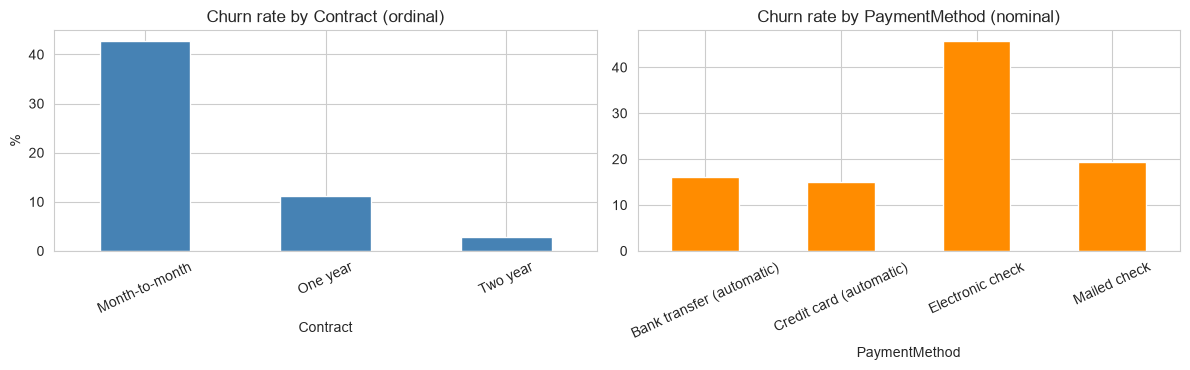

Churn rate by Contract (%): {'Month-to-month': 42.7, 'One year': 11.1, 'Two year': 2.9}
Churn rate by PaymentMethod (%): {'Bank transfer (automatic)': 16.2, 'Credit card (automatic)': 14.9, 'Electronic check': 45.7, 'Mailed check': 19.3}

Contract: churn rate goes down at every step: True


In [3]:
train_df = X_train.assign(Churn=y_train)

contract_order = ordinal_orders["Contract"]
by_contract = train_df.groupby(train_df["Contract"].astype(str))["Churn"].mean().reindex(contract_order) * 100
by_payment = train_df.groupby(train_df["PaymentMethod"].astype(str))["Churn"].mean().sort_index() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
by_contract.plot(kind="bar", ax=axes[0], color="steelblue"); axes[0].set_title("Churn rate by Contract (ordinal)"); axes[0].set_ylabel("%")
by_payment.plot(kind="bar", ax=axes[1], color="darkorange");  axes[1].set_title("Churn rate by PaymentMethod (nominal)")
for ax in axes: ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

print("Churn rate by Contract (%):", by_contract.round(1).to_dict())
print("Churn rate by PaymentMethod (%):", by_payment.round(1).to_dict())
print("\nContract: churn rate goes down at every step:", bool(by_contract.is_monotonic_decreasing))

**What the code does:**
- It joins the training features with the target and calculates the churn rate (the mean of the 0/1 target) for each label of `Contract` and `PaymentMethod`, using only the **training** data.
- `reindex(contract_order)` puts the contracts in their real order. The other column is sorted alphabetically.
- It draws two bar charts and checks with `is_monotonic_decreasing` if the churn rate of `Contract` goes down in every step.

**Why this method was used:** An order that exists in the real world should also show in the behaviour of the customers. If the churn rate changes in one direction along the order, then ordinal numbers (0, 1, 2) describe the column well. For a nominal column, I want to see that the rates are not in any natural line, so a number code would be misleading. I use only the training data for this analysis, because a decision about the encoding is also a decision learned from the data.

**Output meaning:** The churn rate falls clearly from month-to-month to one year and to two years (on the real data), so the order of `Contract` is real and useful. For `PaymentMethod` the rates do not follow any order (on the real data, one method has a much higher rate than the others, and it is not the first or the last in the alphabet). Check your own output.

**Effect on ML:** `Contract` can be one number with an order. `PaymentMethod` needs a method that does not invent an order (one-hot encoding).

## 4. Binary Encoding

**Concept:** A binary variable has two labels, so one column with 0 and 1 is enough. A second column would carry no new information.

- **When to use:** exactly two labels (yes/no, male/female, True/False).
- **When not to use:** three or more labels (the labels cannot be put in one 0/1 column).
- **Advantages:** simple, one column, easy to read.
- **Limitations:** which label is 1 is arbitrary (it changes the sign of a coefficient, not the model), and a missing value needs a decision first.

**Examples:**
- Simple: Yes = 1, No = 0.
- Real-world: a checkbox in a form.
- Business: has the customer a partner?
- AI/ML: booleans are converted to 0/1 by almost every model.

**Implementation:** The booleans from Notebook 2 become integers, `gender` is mapped to 0/1, and I check that nothing is lost.

In [4]:
bool_cols = [c for c in X_train.columns if pd.api.types.is_bool_dtype(X_train[c])]
print("Boolean columns:", bool_cols)

Xb = X_train.copy()
Xb[bool_cols] = Xb[bool_cols].astype(int)
Xb["gender"] = Xb["gender"].astype(str).map({"Male": 0, "Female": 1})

print("\ndtypes before:", X_train[bool_cols + ["gender"]].dtypes.astype(str).to_dict())
print("dtypes after :", Xb[bool_cols + ["gender"]].dtypes.astype(str).to_dict())
print("\nNew missing values created by the mapping:", int(Xb[bool_cols + ["gender"]].isna().sum().sum()))
print("Share of 1 in each column (%):")
print((Xb[bool_cols + ["gender"]].mean() * 100).round(1).to_dict())
print("\nTarget: Churn text -> 0/1 (already done):", df_valid["Churn"].map({"No": 0, "Yes": 1}).astype(int).equals(y))

Boolean columns: ['SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']

dtypes before: {'SeniorCitizen': 'bool', 'Partner': 'bool', 'Dependents': 'bool', 'PhoneService': 'bool', 'PaperlessBilling': 'bool', 'gender': 'category'}
dtypes after : {'SeniorCitizen': 'int64', 'Partner': 'int64', 'Dependents': 'int64', 'PhoneService': 'int64', 'PaperlessBilling': 'int64', 'gender': 'int64'}

New missing values created by the mapping: 0
Share of 1 in each column (%):
{'SeniorCitizen': 16.3, 'Partner': 48.4, 'Dependents': 29.8, 'PhoneService': 90.1, 'PaperlessBilling': 59.1, 'gender': 49.7}

Target: Churn text -> 0/1 (already done): True


**What the code does:**
- It finds the boolean columns by dtype, and converts them to integers with `astype(int)` (True becomes 1, False becomes 0).
- It converts `gender` with `map({"Male": 0, "Female": 1})` after `astype(str)`, because the column is a category.
- It prints the dtypes before and after, the number of missing values that the mapping created, and the share of 1 in each column. The last line checks that the target `Churn` is the same as the mapping No = 0, Yes = 1.

**Why this method was used:** `astype(int)` is safe for a real boolean column, because True and False have only one possible conversion. For text labels I use an explicit `map`, because a label that is not in the dictionary becomes `NaN`, and the check of the missing values would show it (the same logic as in Notebook 2). Using `astype(bool)` on text is the trap that I showed in Notebook 2.

**Before:** five `bool` columns and `gender` as text.

**After:** six integer columns with 0 and 1, and no new missing value.

**Effect on ML:** Binary columns need no more than one column each. Because the mapping is fixed (a rule, not learned), it can be done before the split without any leakage.

## 5. Label Encoding

**Concept:** Label encoding gives each label an integer: 0, 1, 2, and so on. In scikit-learn, `LabelEncoder` is made for the **target** column (the `y`), not for the features. The integers have an order and a distance, so using them for a **nominal feature** gives the model false information.

- **When to use:** the target of a classification (`y`), or a tree-based model with a nominal feature when I accept the risk (trees split by thresholds and are less sensitive).
- **When not to use:** nominal features in linear models, KNN, SVM or neural networks.
- **Advantages:** simple, one column, no increase in the number of columns.
- **Limitations:** invents an order (usually alphabetical) and equal distances.

**Examples:**
- Simple: red = 0, green = 1, blue = 2 (the model thinks that blue is bigger than red).
- Real-world: the class labels of a classification problem.
- Business: the churn label No/Yes of the customers.
- AI/ML: `LabelEncoder().fit_transform(y)`.

**Implementation:** First I use it correctly on the target. Then I use it wrongly on `PaymentMethod`, and compare it with one-hot encoding with a logistic regression (cross-validation on the training data).

In [5]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score
from sklearn.metrics import roc_auc_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

# correct use: the target
le_target = LabelEncoder().fit(df_valid.loc[X_train.index, "Churn"].astype(str))
coded = le_target.transform(df_valid.loc[X_train.index, "Churn"].astype(str))
print("Target classes:", list(le_target.classes_), "->", list(range(len(le_target.classes_))), "| inverse:", le_target.inverse_transform([0, 1]).tolist())

# wrong use: a nominal feature
pm_train = X_train["PaymentMethod"].astype(str)
le_pm = LabelEncoder().fit(pm_train)
codes = pd.Series(le_pm.transform(pm_train), index=pm_train.index, name="code")

table = pd.DataFrame({"label": le_pm.classes_, "code": range(len(le_pm.classes_))})
table["churn_rate_%"] = [round(y_train[pm_train == label].mean() * 100, 1) for label in le_pm.classes_]
print()
print(table.to_string(index=False))
print("\nDistance the model sees: code distance between '" + le_pm.classes_[0] + "' and '" + le_pm.classes_[1] + "' =", 1,
      "| between '" + le_pm.classes_[0] + "' and '" + le_pm.classes_[3] + "' =", 3)

auc_label = cross_val_score(LogisticRegression(max_iter=1000), codes.to_frame(), y_train, cv=cv, scoring="roc_auc").mean()
auc_onehot = cross_val_score(Pipeline([("oh", OneHotEncoder(handle_unknown="ignore")), ("lr", LogisticRegression(max_iter=1000))]),
                             pm_train.to_frame(), y_train, cv=cv, scoring="roc_auc").mean()
print("\nLogistic regression on PaymentMethod only, ROC AUC (5-fold):")
print("  label encoded :", round(auc_label, 4))
print("  one-hot       :", round(auc_onehot, 4))

Target classes: ['No', 'Yes'] -> [0, 1] | inverse: ['No', 'Yes']

                    label  code  churn_rate_%
Bank transfer (automatic)     0          16.2
  Credit card (automatic)     1          14.9
         Electronic check     2          45.7
             Mailed check     3          19.3

Distance the model sees: code distance between 'Bank transfer (automatic)' and 'Credit card (automatic)' = 1 | between 'Bank transfer (automatic)' and 'Mailed check' = 3

Logistic regression on PaymentMethod only, ROC AUC (5-fold):
  label encoded : 0.5694
  one-hot       : 0.6727


**What the code does:**
- `LabelEncoder().fit(...)` learns the list of classes of the target (No, Yes, in alphabetical order), `transform` gives 0 and 1, and `inverse_transform` converts the numbers back to labels.
- For `PaymentMethod` it does the same, and prints a table with each label, its code and its churn rate in the training data. It also prints the distance between codes.
- Then it trains a logistic regression on the label codes of this single column, and another one on its one-hot encoding, and compares the ROC AUC with 5-fold cross-validation.

**Why this method was used:** For the target the label encoder is correct and complete: the model only needs class numbers, and `inverse_transform` returns the labels for the report. For the nominal feature I choose a clear test: a single feature and a linear model. A linear model can only draw one straight line through the code, so if the real effect of the labels is not in the order of the codes, it cannot learn it. The AUC measures how well the feature separates the two classes, and a higher value is better.

**Output meaning:** The codes follow the **alphabet** (Bank transfer = 0, Credit card = 1, Electronic check = 2, Mailed check = 3), and not the behaviour of the customers. The model sees "Mailed check" as three steps from "Bank transfer", which has no meaning. On the real data the churn rate of one payment method is much higher than the rest, and a straight line through the codes cannot represent that, so the one-hot version is expected to have the higher AUC. Check the numbers of your own run.

**Effect on ML:** Label encoding of a nominal feature gives a linear model a wrong shape. It is correct for the target, and acceptable only for models that split by thresholds.

## 6. Ordinal Encoding

**Concept:** Ordinal encoding converts labels with a real order to integers that follow this order (0, 1, 2). In scikit-learn, `OrdinalEncoder` works on **features**, and the order must be given explicitly with `categories=`. Otherwise it uses the alphabetical order, which is often wrong.

- **When to use:** labels with a real order (contract length, education level, size, rating).
- **When not to use:** nominal columns, or an order that is only a convention.
- **Advantages:** one column, keeps the order, and gives a smaller dataset than one-hot.
- **Limitations:** assumes equal distances between the steps, which may not be true.

**Examples:**
- Simple: low = 0, medium = 1, high = 2.
- Real-world: education levels.
- Business: the contract length of a customer.
- AI/ML: `OrdinalEncoder(categories=[[...]])`.

**Implementation:**

In [6]:
# real column: Contract with the order from the business
oe = OrdinalEncoder(categories=[contract_order], handle_unknown="use_encoded_value", unknown_value=-1)
oe.fit(X_train[["Contract"]].astype(str))
contract_codes = oe.transform(X_train[["Contract"]].astype(str)).ravel()
print("Contract codes:", dict(zip(contract_order, range(3))))
print("Share of each code in train:", pd.Series(contract_codes).value_counts(normalize=True).sort_index().round(3).to_dict())

# DEMO: why the order must be given. Alphabetical order is wrong for education levels.
edu = pd.DataFrame({"education": ["High School", "Bachelor", "Master", "PhD", "Bachelor", "High School"]})
default = OrdinalEncoder().fit(edu)
explicit = OrdinalEncoder(categories=[["High School", "Bachelor", "Master", "PhD"]]).fit(edu)
print("\nDEMO education, default (alphabetical):", dict(zip(default.categories_[0], range(4))))
print("DEMO education, explicit order        :", dict(zip(explicit.categories_[0], range(4))))

# compare: ordinal vs one-hot for Contract (logistic regression, 5-fold ROC AUC)
auc_ord = cross_val_score(LogisticRegression(max_iter=1000), contract_codes.reshape(-1, 1), y_train, cv=cv, scoring="roc_auc").mean()
auc_oh = cross_val_score(Pipeline([("oh", OneHotEncoder(handle_unknown="ignore")), ("lr", LogisticRegression(max_iter=1000))]),
                         X_train[["Contract"]].astype(str), y_train, cv=cv, scoring="roc_auc").mean()
print("\nContract only, ROC AUC: ordinal =", round(auc_ord, 4), "| one-hot =", round(auc_oh, 4))

Contract codes: {'Month-to-month': 0, 'One year': 1, 'Two year': 2}
Share of each code in train: {0.0: 0.551, 1.0: 0.208, 2.0: 0.241}

DEMO education, default (alphabetical): {'Bachelor': 0, 'High School': 1, 'Master': 2, 'PhD': 3}
DEMO education, explicit order        : {'High School': 0, 'Bachelor': 1, 'Master': 2, 'PhD': 3}

Contract only, ROC AUC: ordinal = 0.7396 | one-hot = 0.7396


**What the code does:**
- `OrdinalEncoder(categories=[contract_order])` is given the real order of the contracts. `handle_unknown="use_encoded_value", unknown_value=-1` tells it to give -1 to a label that was not in the training data, instead of stopping with an error. It is fitted on the **training** data and applied with `transform`.
- It prints the codes and the share of each code.
- The education example (demo) shows what the default does: it sorts the labels alphabetically, so "Bachelor" gets 0 and "High School" gets 1, which is wrong. With the explicit order the codes follow the real levels.
- It compares ordinal and one-hot encoding of `Contract` with the same logistic regression.

**Why this method was used:** I give the order by hand because the encoder cannot know it. For `Contract` the alphabetical order (Month-to-month, One year, Two year) is correct only by luck, and the education demo shows that this luck is not a rule. The comparison with one-hot answers the practical question: does the single ordinal column keep the information that three one-hot columns have?

**Output meaning:** The codes 0, 1 and 2 follow the contract length. The ordinal and the one-hot AUC are close to each other for `Contract` (on the real data, the churn rate falls at each step, so one ordinal column is almost as good as three columns). When they are almost equal, the simpler representation is preferred.

**Effect on ML:** The ordinal encoding gives one column that keeps the order. I choose it for `Contract`, and I keep the one-hot version as the alternative that I can use if a model needs unequal distances.

## 7. One-Hot Encoding

**Concept:** One-hot encoding creates one new 0/1 column for each label. In each row exactly one of these columns is 1. It does not invent an order or a distance, so it is the standard choice for nominal features.

- **When to use:** nominal features with a small number of labels (up to about 10 to 15).
- **When not to use:** high-cardinality columns (hundreds of labels), because the number of columns explodes.
- **Advantages:** no false order, works with every model, easy to understand.
- **Limitations:** increases the number of columns, creates sparse data, and the columns are linearly dependent (see the dummy variable trap).

**Examples:**
- Simple: colour = red becomes [1, 0, 0], green becomes [0, 1, 0].
- Real-world: the country of a customer.
- Business: the payment method of a customer.
- AI/ML: `OneHotEncoder(handle_unknown="ignore")` or `pd.get_dummies`.

**Implementation:** I use `OneHotEncoder` fitted on the training data, and I also show the problem of `pd.get_dummies` when a label is missing in the test data.

In [7]:
onehot_cols = ["InternetService", "PaymentMethod"]
ohe = OneHotEncoder(handle_unknown="ignore")
ohe.fit(X_train[onehot_cols].astype(str))

train_oh = ohe.transform(X_train[onehot_cols].astype(str)).toarray()
test_oh = ohe.transform(X_test[onehot_cols].astype(str)).toarray()

print("Columns before:", len(onehot_cols), "| after:", train_oh.shape[1])
print("New columns:", list(ohe.get_feature_names_out()))
print("Each row has exactly one 1 per original column:", bool((train_oh.sum(axis=1) == len(onehot_cols)).all()))
print("Train and test have the same columns:", train_oh.shape[1] == test_oh.shape[1])

# the get_dummies problem
train_d = pd.get_dummies(X_train["PaymentMethod"].astype(str))
subset = X_test[X_test["PaymentMethod"].astype(str) != "Mailed check"]
test_d = pd.get_dummies(subset["PaymentMethod"].astype(str))
print("\npd.get_dummies on train:", list(train_d.columns))
print("pd.get_dummies on a test subset without 'Mailed check':", list(test_d.columns))
print("Same columns:", list(train_d.columns) == list(test_d.columns))
print("OneHotEncoder on the same subset ->", ohe.transform(subset[onehot_cols].astype(str)).shape[1], "columns (same as train)")

Columns before: 2 | after: 7
New columns: ['InternetService_DSL', 'InternetService_Fiber optic', 'InternetService_No', 'PaymentMethod_Bank transfer (automatic)', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']
Each row has exactly one 1 per original column: True
Train and test have the same columns: True

pd.get_dummies on train: ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
pd.get_dummies on a test subset without 'Mailed check': ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check']
Same columns: False
OneHotEncoder on the same subset -> 7 columns (same as train)


**What the code does:**
- `OneHotEncoder(handle_unknown="ignore")` is fitted on the training columns `InternetService` and `PaymentMethod`. It learns the list of labels of each column.
- `transform` converts the train and the test data. The code prints the number of columns before and after, the names of the new columns, a check that each row has exactly one 1 for each original column, and a check that train and test have the same columns.
- Then it shows the problem of `pd.get_dummies`: when a test subset does not contain one label, the dummies of the test data have fewer columns than the training dummies.

**Why this method was used:** `OneHotEncoder` stores the list of labels learned from the training data, so it creates the same columns for any new data. `pd.get_dummies` learns nothing: it looks at the data it receives, so train and test can get different columns, and the model would receive a matrix with a wrong shape or with columns in the wrong place, silently. `handle_unknown="ignore"` is a protection for a label that is new in the test data (Section 11). The `fit` is done on the training data only, so no information from the test set is used.

**Before:** two text columns with 3 and 4 labels.

**After:** seven 0/1 columns (3 + 4), with exactly one 1 per original column.

**Effect on ML:** The model sees each label as an independent yes/no feature, without any false order. In a pipeline I always use the encoder object, and not `get_dummies`.

## 8. Dummy Variables (the Dummy Variable Trap)

**Concept:** Dummy variables are one-hot columns where one label is dropped (`drop="first"`). If a column has k labels, k - 1 columns are enough: when all the others are 0, the row belongs to the dropped label. If all k columns are kept together with an intercept, one column can be calculated from the others (they sum to 1). This perfect dependency is the **dummy variable trap** (perfect multicollinearity).

- **When to use `drop="first"`:** linear and logistic regression without regularisation, and when I want to interpret the coefficients.
- **When not to use:** tree-based models (they do not need it), or when the dropped label would be hard to explain.
- **Advantages:** removes the perfect dependency, and gives fewer columns.
- **Limitations:** the dropped label becomes the reference, so coefficients are relative to it, and unknown labels are mapped to the reference.

**Examples:**
- Simple: gender with two labels needs only one column.
- Real-world: a survey with 4 regions needs 3 columns.
- Business: the payment method with 4 labels needs 3 columns.
- AI/ML: scikit-learn has `drop="first"` and `drop="if_binary"`.

**Implementation:** I check the dependency with the matrix rank.

In [8]:
service = X_train[["InternetService"]].astype(str)

full = OneHotEncoder().fit_transform(service).toarray()
with_intercept = np.column_stack([np.ones(len(full)), full])
print("All 3 dummy columns + intercept:", with_intercept.shape[1], "columns | matrix rank:", np.linalg.matrix_rank(with_intercept),
      "-> one column is redundant")

dropped = OneHotEncoder(drop="first").fit_transform(service).toarray()
with_intercept2 = np.column_stack([np.ones(len(dropped)), dropped])
print("2 dummy columns (drop first) + intercept:", with_intercept2.shape[1], "columns | matrix rank:", np.linalg.matrix_rank(with_intercept2),
      "-> no redundancy")

ohe_drop = OneHotEncoder(drop="first").fit(service)
print("\nDropped label (the reference):", ohe_drop.categories_[0][0], "| columns kept:", list(ohe_drop.get_feature_names_out()))

binary_gender = OneHotEncoder(drop="if_binary").fit(X_train[["gender"]].astype(str))
print("drop='if_binary' on gender:", list(binary_gender.get_feature_names_out()), "(one column)")

All 3 dummy columns + intercept: 4 columns | matrix rank: 3 -> one column is redundant
2 dummy columns (drop first) + intercept: 3 columns | matrix rank: 3 -> no redundancy

Dropped label (the reference): DSL | columns kept: ['InternetService_Fiber optic', 'InternetService_No']
drop='if_binary' on gender: ['gender_Male'] (one column)


**What the code does:**
- It one-hot encodes `InternetService` (3 labels) and adds a column of ones (the intercept of a linear model). Then it calculates the **matrix rank**, which is the number of columns that are independent of each other.
- It repeats this with `drop="first"`, which leaves 2 dummy columns.
- It prints the dropped label (the reference) and the kept columns, and shows `drop="if_binary"`, which drops one column only for binary features.

**Why this method was used:** The rank is a direct, numeric proof of the trap. If the rank is smaller than the number of columns, at least one column is a combination of the others. Then a linear model without regularisation has no unique solution, and its coefficients are unstable. `drop="first"` is the simple fix. `drop="if_binary"` is useful because it keeps three-label columns complete and makes two-label columns a single 0/1 column.

**Output meaning:** With all three dummy columns plus the intercept there are 4 columns but the rank is only 3, so one column is redundant. With `drop="first"` there are 3 columns and the rank is 3.

**Effect on ML:** For tree models the extra column does no harm. For a linear model I use `drop="first"` or a regularised model. In this project the binary columns are already one 0/1 column each, and the nominal columns (`InternetService`, `PaymentMethod`) get the complete one-hot encoding, because I plan to use trees or regularised models (the logistic regression of scikit-learn is regularised by default). If I later use an unregularised linear model, I switch to `drop="first"`.

## 9. Frequency Encoding

**Concept:** Frequency encoding replaces each label with the share (or the count) of rows that have this label in the **training data**. It gives one numeric column, whatever the number of labels.

- **When to use:** high-cardinality nominal features, when the frequency itself has a meaning (popular items vs rare items), and with tree models.
- **When not to use:** when two different labels have the same frequency and I need to tell them apart, or when the frequency is not related to the target.
- **Advantages:** one column, simple, no target is used (no target leakage).
- **Limitations:** different labels with the same frequency get the same number, and the frequency can change in new data.

**Examples:**
- Simple: a label that appears in 40% of the rows becomes 0.4.
- Real-world: the popularity of a product.
- Business: how common is the payment method of a customer.
- AI/ML: a quick encoding for high-cardinality features in tree models.

**Implementation:**

In [9]:
pm_train = X_train["PaymentMethod"].astype(str)
pm_test = X_test["PaymentMethod"].astype(str)

freq = pm_train.value_counts(normalize=True)            # learned from the TRAIN data only
enc_train = pm_train.map(freq)
enc_test = pm_test.map(freq).fillna(0)                   # a label that is new in the test data gets 0

print("Frequency map learned on train:")
print(freq.round(3).to_dict())
print("\nTest values encoded with the train map:", enc_test.round(3).value_counts().sort_index().to_dict())
print("Unknown labels in test:", int(pm_test.map(freq).isna().sum()))

# DEMO: two labels with the same frequency cannot be told apart
demo = pd.Series(["A", "A", "B", "B", "C", "C", "C", "D"])
print("\nDEMO frequencies:", demo.map(demo.value_counts(normalize=True)).tolist(), "-> A and B both get 0.25 (they cannot be separated)")

Frequency map learned on train:
{'Electronic check': 0.336, 'Mailed check': 0.228, 'Bank transfer (automatic)': 0.221, 'Credit card (automatic)': 0.215}

Test values encoded with the train map: {0.215: 309, 0.221: 300, 0.228: 326, 0.336: 474}
Unknown labels in test: 0

DEMO frequencies: [0.25, 0.25, 0.25, 0.25, 0.375, 0.375, 0.375, 0.125] -> A and B both get 0.25 (they cannot be separated)


**What the code does:**
- `value_counts(normalize=True)` on the training column gives the share of each label. `map(freq)` replaces each label by its share.
- The same map (learned on train) is applied to the test data. A label that does not exist in the map would become `NaN`, so `fillna(0)` gives it the frequency 0 (it was never seen). The code counts the unknown labels.
- The small demo shows the main weakness: labels A and B have the same count, so they get the same number.

**Why this method was used:** The map is calculated on the training set and only **applied** to the test set, so the test data does not influence the numbers. The frequency does not use the target, so there is no target leakage. The fallback 0 for an unknown label is a deliberate choice: "never seen" is also a form of rare.

**Output meaning:** The four payment methods become four numbers between about 0.2 and 0.34 (the exact values depend on the data), and there are no unknown labels in the test set. The demo shows that equal frequencies produce equal codes.

**Effect on ML:** Frequency encoding is a compact choice for many labels, but it is not a good choice for `PaymentMethod`, where the labels have clear different meanings and only four labels exist.

## 10. Target Encoding

**Concept:** Target encoding replaces each label with the average of the target for this label (here: the churn rate of the label). It uses the target, so it carries the most direct information about the relation between the label and the target, with only one column. The big danger is **target leakage**: if the average is calculated with the same rows that it is applied to, each row sees its own target, and the model looks better than it is.

To avoid it I use two protections:
- **Smoothing:** `(count x mean_label + m x global_mean) / (count + m)`. A label with few rows is pulled to the global mean, because its own mean is not reliable.
- **Out-of-fold encoding:** the training rows are encoded with a mean that is calculated on the **other folds**, and the test rows are encoded with the map of the whole training set.

- **When to use:** high-cardinality nominal features that are related to the target.
- **When not to use:** small data, and without the protections above.
- **Advantages:** one column, strong signal, no explosion of columns.
- **Limitations:** leakage if used wrongly, noisy for rare labels, and more complex.

**Examples:**
- Simple: if 30% of the customers of a city churn, the city becomes 0.30.
- Real-world: the average price of a neighbourhood.
- Business: the churn risk of a sales region.
- AI/ML: scikit-learn has `TargetEncoder` (version 1.3 or later) that does the cross-fitting inside `fit_transform`. I write it by hand to understand it.

**Implementation:** I test it with a demo feature that has **no relation to the target** (random noise IDs with 3000 labels). A correct encoder must find no signal in it (an AUC of about 0.5).

In [10]:
def target_encode_map(cat, target, smoothing=20):
    prior = target.mean()
    stats = target.groupby(cat).agg(["mean", "count"])
    smooth = (stats["count"] * stats["mean"] + smoothing * prior) / (stats["count"] + smoothing)
    return smooth, prior

def apply_map(cat, mapping, prior):
    return cat.map(mapping).fillna(prior)              # an unknown label gets the global mean

def oof_encode(cat, target, n_splits=5, smoothing=20):
    out = pd.Series(np.nan, index=cat.index)
    for fit_idx, apply_idx in KFold(n_splits, shuffle=True, random_state=0).split(cat):
        mapping, prior = target_encode_map(cat.iloc[fit_idx], target.iloc[fit_idx], smoothing)
        out.iloc[apply_idx] = apply_map(cat.iloc[apply_idx], mapping, prior).to_numpy()
    return out

rng = np.random.default_rng(3)

# real feature: PaymentMethod
m, p = target_encode_map(pm_train, y_train)
print("PaymentMethod target encoding (smoothed churn rate):", m.round(3).to_dict(), "| global rate:", round(p, 3))

# DEMO: a feature with no signal (random IDs), the leakage test
noise_train = pd.Series(rng.integers(0, 3000, len(X_train)).astype(str), index=X_train.index)
noise_test = pd.Series(rng.integers(0, 3000, len(X_test)).astype(str), index=X_test.index)

mapping, prior = target_encode_map(noise_train, y_train, smoothing=1)
naive_train = apply_map(noise_train, mapping, prior)                  # WRONG: each row sees its own target
naive_test = apply_map(noise_test, mapping, prior)
oof_train = oof_encode(noise_train, y_train, smoothing=1)             # CORRECT: encoded by the other folds

rows = [("naive (same rows used to fit and apply)", roc_auc_score(y_train, naive_train), roc_auc_score(y_test, naive_test)),
        ("out-of-fold", roc_auc_score(y_train, oof_train), roc_auc_score(y_test, naive_test))]
print("\nDEMO noise feature with 3000 labels - ROC AUC of the encoded value alone (0.5 = no signal):")
print(pd.DataFrame(rows, columns=["method", "AUC on train", "AUC on test"]).round(3).to_string(index=False))

PaymentMethod target encoding (smoothed churn rate): {'Bank transfer (automatic)': 0.163, 'Credit card (automatic)': 0.151, 'Electronic check': 0.455, 'Mailed check': 0.194} | global rate: 0.265

DEMO noise feature with 3000 labels - ROC AUC of the encoded value alone (0.5 = no signal):
                                 method  AUC on train  AUC on test
naive (same rows used to fit and apply)         0.901        0.461
                            out-of-fold         0.493        0.461


**What the code does:**
- `target_encode_map` calculates, for each label, the mean of the target and the number of rows, and applies the smoothing formula. It also returns the global mean (`prior`).
- `apply_map` replaces the labels with the encoded numbers. A label that was not in the map gets the global mean.
- `oof_encode` splits the training rows in 5 folds. For each fold it learns the map on the **other four folds**, and applies it to the fold. In this way no row is encoded with its own target.
- For `PaymentMethod` it prints the smoothed churn rate of each label.
- For the random demo feature it compares the naive way and the out-of-fold way, with the ROC AUC of the encoded value alone on the training and on the test data.

**Why this method was used:** The random feature has no relation to the churn, so a correct method must give an AUC of about 0.5 on both train and test. The naive method fails this test in a clear way, and this is the proof of the leakage. Smoothing is needed for the rare labels, but I use a very small smoothing value (1) here on purpose, to make the leakage easy to see. The out-of-fold encoding is the standard protection, and the same idea is used inside scikit-learn's `TargetEncoder`.

**Output meaning:** With the naive method the AUC on the training data is very high (the encoder memorised the target of the rows, with almost 2 rows per label), but on the test data it is about 0.5, so there was never any signal. With the out-of-fold encoding the AUC on the training data is also about 0.5, which is the honest value. For `PaymentMethod` the smoothed rates are close to the real churn rates, because each label has many rows.

**Effect on ML:** Target encoding can give a model a very strong feature, but if I fit it incorrectly, the training score is false and the model fails on new data. It must be fitted inside the training fold, with smoothing, and it belongs in a pipeline.

## 11. Handling Unknown Categories

**Concept:** An unknown category is a label that appears in new data (validation, test or production) but was not in the training data. The encoder was never told what to do with it, so the behaviour depends on the settings.

| Encoder | Option | What happens |
|---|---|---|
| `OneHotEncoder` | `handle_unknown="error"` (default) | stops with an error |
| `OneHotEncoder` | `handle_unknown="ignore"` | all the dummy columns are 0 for the row |
| `OrdinalEncoder` | `handle_unknown="use_encoded_value", unknown_value=-1` | the code -1 |
| Frequency encoding | `fillna(0)` | frequency 0 (never seen) |
| Target encoding | `fillna(global mean)` | the global average |

**Examples:**
- Simple: a new payment method "Cash" appears.
- Real-world: a new country in a new customer list.
- Business: the company starts a new contract type.
- AI/ML: a pipeline that stops with an error at night is worse than a pipeline that handles the label in a defined way and logs it.

**Implementation:** I create a test row with a label that is not in the training data (a demo label "Cash") and I check what each encoder does.

In [11]:
unseen = X_test[["PaymentMethod"]].astype(str).head(3).copy()
unseen.iloc[0, 0] = "Cash"                                                    # DEMO: a label the encoder has never seen
print("Test rows:", unseen["PaymentMethod"].tolist())

strict = OneHotEncoder(handle_unknown="error").fit(pm_train.to_frame())
try:
    strict.transform(unseen)
except Exception as e:
    print("\nOneHot, handle_unknown='error'  ->", type(e).__name__)

ignore = OneHotEncoder(handle_unknown="ignore").fit(pm_train.to_frame())
print("OneHot, handle_unknown='ignore'  ->", ignore.transform(unseen).toarray()[0].tolist(), "(all zeros for 'Cash')")

ordinal = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit(pm_train.to_frame())
print("Ordinal, unknown_value=-1        ->", ordinal.transform(unseen).ravel().tolist())

print("Frequency, fillna(0)             ->", unseen["PaymentMethod"].map(freq).fillna(0).round(3).tolist())
print("Target, global mean              ->", apply_map(unseen["PaymentMethod"], m, p).round(3).tolist())

Test rows: ['Cash', 'Credit card (automatic)', 'Credit card (automatic)']

OneHot, handle_unknown='error'  -> ValueError
OneHot, handle_unknown='ignore'  -> [0.0, 0.0, 0.0, 0.0] (all zeros for 'Cash')
Ordinal, unknown_value=-1        -> [-1.0, 1.0, 1.0]
Frequency, fillna(0)             -> [0.0, 0.215, 0.215]
Target, global mean              -> [0.265, 0.151, 0.151]


**What the code does:** It takes three rows of the test data, and changes the first one to a label that the encoders have never seen ("Cash", a demo label). Then it sends the same rows to each encoder: one-hot with `error`, one-hot with `ignore`, the ordinal encoder with `unknown_value=-1`, the frequency map with 0, and the target map with the global mean.

**Why this method was used:** Unknown labels are rare in the data that I have today and common in production, so the only way to know what happens is to test it on purpose. I put the unknown label in the first row, and the other two rows are normal, to see that only the first row is different.

**Output meaning:** The strict one-hot encoder stops with an error. With `ignore` the row for "Cash" is all zeros, and the other rows are normal. The ordinal encoder gives -1, the frequency map gives 0 and the target map gives the global churn rate.

**Insight obtained:** Each choice says something different: all zeros mean "not any of the known labels", -1 is a special code, 0 means "never seen", and the global mean means "no information". They are all better than stopping the pipeline, but a new label must also be logged, because a model that sees many new labels needs to be retrained.

**Effect on ML:** I use `handle_unknown="ignore"` for the one-hot encoder and `unknown_value=-1` for the ordinal encoder in the final workflow. The strict mode is useful only while I develop and want to be warned.

## 12. High-Cardinality Categories

**Concept:** A high-cardinality feature has many different labels (hundreds or thousands): city, zip code, product ID, customer ID. One-hot encoding would create one column per label, which makes the data huge and sparse, makes the model slow, and increases the risk of overfitting.

| Option | Idea | Columns |
|---|---|---|
| Drop the feature | an identifier carries no general information | 0 |
| Group the rare labels | keep the top N labels, the rest become "Other" | N + 1 |
| Frequency encoding | the share of the label | 1 |
| Target encoding (out-of-fold, smoothed) | the churn rate of the label | 1 |
| Hashing | a fixed number of columns, labels are hashed into them | fixed (for example 16) |

**Examples:**
- Simple: a column with 1000 different cities.
- Real-world: a product ID in an online shop.
- Business: the zip code of a customer.
- AI/ML: the `customerID` column has 7043 labels, one per row, so it can only memorise the rows.

**Implementation:** First I show the problem for the real `customerID`. Then I use a demo table with 200 cities (more frequent and rare ones, each with its own churn effect) and compare the options.

In [12]:
from sklearn.feature_extraction import FeatureHasher

# real: customerID
n_ids = df_valid["customerID"].nunique()
print("customerID labels:", n_ids, "| rows:", len(df_valid))
print("One-hot would create", n_ids, "columns, about", round(len(X_train) * n_ids * 8 / 1e6), "MB as a dense float matrix -> the column is dropped, not encoded")

# DEMO: 200 cities with a few big ones and many small ones, and a churn effect for each city
rng = np.random.default_rng(8)
n, n_cities = 7043, 200
weights = 1 / np.arange(1, n_cities + 1)
city_idx = rng.choice(n_cities, size=n, p=weights / weights.sum())
effect = rng.normal(0, 1, n_cities)
churn_geo = (rng.random(n) < 1 / (1 + np.exp(-(effect[city_idx] - 1)))).astype(int)
city = pd.Series(np.array(["city_" + str(i) for i in range(n_cities)])[city_idx])

c_train, c_test, g_train, g_test = train_test_split(city, pd.Series(churn_geo), test_size=0.2, stratify=churn_geo, random_state=1)
print("\nDEMO cities: labels in train =", c_train.nunique(), "| rows per label (median) =", int(c_train.value_counts().median()),
      "| labels seen only once =", int((c_train.value_counts() == 1).sum()))

def evaluate(Xtr, Xte):
    model = LogisticRegression(max_iter=2000).fit(Xtr, g_train)
    return roc_auc_score(g_test, model.predict_proba(Xte)[:, 1])

rows = []

oh = OneHotEncoder(handle_unknown="ignore").fit(c_train.to_frame())
rows.append(("one-hot (all labels)", oh.transform(c_train.to_frame()).shape[1], evaluate(oh.transform(c_train.to_frame()), oh.transform(c_test.to_frame()))))

top = c_train.value_counts().head(10).index
group = lambda s: s.where(s.isin(top), "Other").to_frame()
oh2 = OneHotEncoder(handle_unknown="ignore").fit(group(c_train))
rows.append(("top 10 labels + Other", oh2.transform(group(c_train)).shape[1], evaluate(oh2.transform(group(c_train)), oh2.transform(group(c_test)))))

f = c_train.value_counts(normalize=True)
rows.append(("frequency", 1, evaluate(c_train.map(f).to_frame(), c_test.map(f).fillna(0).to_frame())))

mp, pr = target_encode_map(c_train, g_train, smoothing=20)
rows.append(("target (out-of-fold, smoothed)", 1, evaluate(oof_encode(c_train, g_train).to_frame(), apply_map(c_test, mp, pr).to_frame())))

hasher = FeatureHasher(n_features=16, input_type="string")
rows.append(("hashing (16 columns)", 16, evaluate(hasher.transform([[c] for c in c_train]), hasher.transform([[c] for c in c_test]))))

print()
print(pd.DataFrame(rows, columns=["encoding", "columns", "test AUC"]).round(4).to_string(index=False))

customerID labels: 7043 | rows: 7043
One-hot would create 7043 columns, about 317 MB as a dense float matrix -> the column is dropped, not encoded

DEMO cities: labels in train = 198 | rows per label (median) = 10 | labels seen only once = 1

                      encoding  columns  test AUC
          one-hot (all labels)      198    0.6854
         top 10 labels + Other       11    0.5754
                     frequency        1    0.5150
target (out-of-fold, smoothed)        1    0.6755
          hashing (16 columns)       16    0.5897


**What the code does:**
- For the real `customerID` it prints the number of labels (one per row) and the memory that a dense one-hot matrix would need.
- For the demo it creates 200 cities where a few cities are very frequent (the weights follow 1/rank) and most are rare, gives each city a random effect on the churn, and generates a target from it. It splits the demo in train and test.
- `evaluate` trains a logistic regression on a given encoding and returns the test ROC AUC.
- It compares five encodings: one-hot of all the labels, the 10 most frequent labels plus "Other", frequency, out-of-fold smoothed target encoding, and `FeatureHasher` with 16 columns. The table shows the number of columns and the test AUC.

**Why this method was used:** The demo is built so that the label really has a relation with the target, so the encodings can be compared on how much of this information they keep, and at what cost in columns. All the encodings are learned on the training data and evaluated on the test data. The out-of-fold version of target encoding is used so that its result is honest. The `customerID` has no relation to the churn (it is only a name), so it is dropped. A model with 7043 labels could only memorise its rows.

**Output meaning:** One-hot of all labels needs about 200 columns. Grouping to 11 columns, frequency (1 column) and hashing (16 columns) keep different parts of the information. Target encoding gives one column and in this demo is expected to keep the most information per column, because the city effect **is** the signal. The frequency encoding is expected to be weak here, because how common a city is has no relation to its churn effect in my demo. The exact order depends on the random numbers, so check your own table.

**Effect on ML:** There is no single best option. For a feature with a real relation to the target and many labels, target encoding (with protection) is strong and compact. Grouping is easy to explain, and hashing keeps the size fixed. An identifier is dropped.

## 13. Decision for the Telco Data

There is one open question from Sprint 4 and Notebook 5: the labels "No internet service" and "No phone service". `InternetService = No` already says that the customer has no internet, so the label "No internet service" in the six add-on columns repeats it. The same is true for `PhoneService` and `MultipleLines`. I compare two representations with the same model:
- **A:** keep the three labels and one-hot encode them.
- **B:** merge the repeated label into "No", so each of the seven columns becomes a binary 0/1 column.

For both, the other columns are encoded in the same way, and a logistic regression is evaluated with 5-fold cross-validation on the training data. (The scaling of the numeric columns is only used here so that the model converges. The scaling topic is Notebook 8.)

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
service_cols = ["MultipleLines"] + addons
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
bool_cols = ["SeniorCitizen", "Partner", "Dependents", "PhoneService", "PaperlessBilling"]

def basic_binary(data):
    # fixed rules (no learning): safe before the split
    out = data.copy()
    out[bool_cols] = out[bool_cols].astype(int)
    out["gender"] = out["gender"].astype(str).map({"Male": 0, "Female": 1})
    for c in ["InternetService", "PaymentMethod", "Contract"] + service_cols:
        out[c] = out[c].astype(str)
    return out

def merge_service_labels(data):
    out = data.copy()
    for c in service_cols:
        out[c] = out[c].astype(str).replace({"No internet service": "No", "No phone service": "No"})
    return out

def prepare_A(data):
    return basic_binary(data)

def prepare_B(data):
    out = basic_binary(merge_service_labels(data))
    for c in service_cols:
        out[c] = (out[c] == "Yes").astype(int)
    return out

def make_pre(variant, scale=True):
    onehot = ["InternetService", "PaymentMethod"] + (service_cols if variant == "A" else [])
    keep = bool_cols + ["gender"] + ([] if variant == "A" else service_cols)
    return ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", num_cols),
        ("onehot", OneHotEncoder(handle_unknown="ignore"), onehot),
        ("contract", OrdinalEncoder(categories=[contract_order], handle_unknown="use_encoded_value", unknown_value=-1), ["Contract"]),
        ("keep", "passthrough", keep),
    ], verbose_feature_names_out=False)

rows = []
for variant, prep in [("A  keep 3 labels, one-hot", prepare_A), ("B  merge into No, binary", prepare_B)]:
    pre = make_pre(variant[0])
    pipe = Pipeline([("pre", pre), ("lr", LogisticRegression(max_iter=2000))])
    Xp = prep(X_train)
    scores = cross_val_score(pipe, Xp, y_train, cv=cv, scoring="roc_auc")
    n_features = make_pre(variant[0]).fit(Xp).transform(Xp).shape[1]
    rows.append((variant, n_features, round(scores.mean(), 4), round(scores.std(), 4)))
print(pd.DataFrame(rows, columns=["representation", "features", "AUC mean (5-fold)", "AUC std"]).to_string(index=False))

           representation  features  AUC mean (5-fold)  AUC std
A  keep 3 labels, one-hot        38             0.8462   0.0117
 B  merge into No, binary        24             0.8462   0.0118


**What the code does:**
- `basic_binary` applies the fixed rules: booleans to 0/1, `gender` to 0/1, and the other categorical columns to plain text.
- `merge_service_labels` replaces "No internet service" and "No phone service" with "No" in the seven service columns.
- `prepare_A` keeps the three labels. `prepare_B` merges the labels and then converts the seven columns to 0/1 (Yes = 1).
- `make_pre` builds a `ColumnTransformer` for each variant: the numeric columns are scaled (only for this comparison), the nominal columns are one-hot encoded, `Contract` is ordinal, and the binary columns pass through unchanged.
- Each variant is put in a pipeline with a logistic regression and evaluated with 5-fold cross-validation. The table shows the number of features and the AUC.

**Why this method was used:** The question is whether the merge loses information, so I compare the same model on both versions. The merge is a fixed rule (it does not learn anything from the data), so it is safe to do before the split. The encoders that learn (the one-hot and the ordinal) are inside a pipeline, so in each fold they are fitted on the training part only.

**Output meaning:** The AUC of A and B is almost the same (the difference is within the standard deviation), but B has fewer features (the 7 service columns become 7 binary columns instead of 21 one-hot columns). Check your own numbers.

**Decision:** I choose **B**. When two representations give almost the same performance, I take the simpler one: fewer columns, no redundant information, and every column can be read directly (Yes = 1). No information is lost, because `InternetService = No` and `PhoneService = 0` stay in the data and still say that the customer has no such service.

| Column group | Encoding | Reason |
|---|---|---|
| 5 boolean columns | 0/1 | binary |
| `gender` | 0/1 | binary (nominal with two labels) |
| `MultipleLines` and 6 add-ons | 0/1 after merging "No ... service" into "No" | binary, repeated information removed |
| `InternetService`, `PaymentMethod` | one-hot, `handle_unknown="ignore"` | nominal, few labels |
| `Contract` | ordinal (0, 1, 2), unknown = -1 | real order, churn falls at each step |
| `tenure`, `MonthlyCharges`, `TotalCharges` | unchanged here, scaled in Notebook 8 | numeric |
| `customerID` | dropped | identifier |
| `Churn` | 0/1 | target |

**Effect on ML:** The final encoder uses only fixed rules and encoders that are fitted on the training data. Now I build it.

In [14]:
final_encoder = make_pre("B", scale=False)                 # numeric columns pass through, scaling is Notebook 8

X_train_p, X_test_p = prepare_B(X_train), prepare_B(X_test)
final_encoder.fit(X_train_p)                              # learned on the training data only

def to_frame(encoded, index):
    encoded = encoded.toarray() if hasattr(encoded, "toarray") else encoded
    return pd.DataFrame(encoded, columns=final_encoder.get_feature_names_out(), index=index)

X_train_enc = to_frame(final_encoder.transform(X_train_p), X_train.index)
X_test_enc = to_frame(final_encoder.transform(X_test_p), X_test.index)

print("Before encoding:", X_train.shape, "| after encoding:", X_train_enc.shape, "| test:", X_test_enc.shape)
print("dtypes after:", X_train_enc.dtypes.astype(str).value_counts().to_dict())
print("Missing values (train/test):", int(X_train_enc.isna().sum().sum()), "/", int(X_test_enc.isna().sum().sum()))
print("Same columns in train and test:", list(X_train_enc.columns) == list(X_test_enc.columns))
print("Every InternetService row has exactly one 1:", bool((X_train_enc.filter(like="InternetService_").sum(axis=1) == 1).all()))
print("Contract codes:", sorted(X_train_enc["Contract"].unique().tolist()))
print("\nFeatures:", list(X_train_enc.columns))
X_train_enc.head(3)

Before encoding: (5634, 19) | after encoding: (5634, 24) | test: (1409, 24)
dtypes after: {'float64': 24}
Missing values (train/test): 0 / 0
Same columns in train and test: True
Every InternetService row has exactly one 1: True
Contract codes: [0.0, 1.0, 2.0]

Features: ['tenure', 'MonthlyCharges', 'TotalCharges', 'InternetService_DSL', 'InternetService_Fiber optic', 'InternetService_No', 'PaymentMethod_Bank transfer (automatic)', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'Contract', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'gender', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']


,tenure,MonthlyCharges,TotalCharges,InternetService_DSL,InternetService_Fiber optic,InternetService_No,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,...,PhoneService,PaperlessBilling,gender,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
3738,35.0,49.20,1701.65,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0
3151,15.0,75.10,1151.55,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4860,13.0,40.55,590.35,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0


**What the code does:**
- `make_pre("B", scale=False)` builds the final encoder: the numeric columns pass through (they are scaled in Notebook 8), the two nominal columns are one-hot encoded, `Contract` is ordinal, and the binary columns pass through.
- `prepare_B` applies the fixed rules to the training and the test features. Then `final_encoder.fit` learns the labels from the **training** data only, and `transform` is applied to both.
- `to_frame` turns the result into a dataframe with readable column names (`get_feature_names_out`) and the original row index. It handles the case where the encoder returns a sparse matrix.
- It prints the shapes, the dtypes, the number of missing values, a check that train and test have the same columns, a check that the one-hot columns of `InternetService` sum to 1 in every row, and the codes of `Contract`.

**Why this method was used:** The encoder is fitted once on the training data and then only applied, so the test set has no influence on the categories. Returning a dataframe with names is important, because later (feature selection, feature importance) I need to know which column is which. The checks after the transformation are cheap validations: no missing values, only numbers, the same columns in train and test.

**Before:** 19 feature columns with text, booleans and categories.

**After:** 24 numeric columns (3 numeric, 13 binary, 7 one-hot, 1 ordinal), no missing values, and the same columns in train and test.

**Effect on ML:** The data is now fully numeric, so a model can be trained. Scaling and the other transformations come in the next notebooks, and all the steps will be combined in a single pipeline in Notebook 14.

In [15]:
merge_service_labels(df_valid).to_csv("telco_step7_service_labels_merged.csv", index=False)
X_train_enc.assign(Churn=y_train).to_csv("telco_step7_train_encoded.csv")
X_test_enc.assign(Churn=y_test).to_csv("telco_step7_test_encoded.csv")
print("saved: service labels merged, encoded train and encoded test")

if os.path.exists("data_quality_issue_log.csv"):
    log = pd.read_csv("data_quality_issue_log.csv")
    log.loc[log["id"] == 4, "status"] = "done (Notebook 7): merged into No, binary"
    log.to_csv("data_quality_issue_log.csv", index=False)
    print(log[["id", "column", "problem", "status"]].head(4))
else:
    print("data_quality_issue_log.csv not found (run Notebook 1 first)")

saved: service labels merged, encoded train and encoded test
   id                           column                            problem                                     status
0   1                     TotalCharges                     stored as text                          done (Notebook 2)
1   2                     TotalCharges           11 hidden missing values                          done (Notebook 3)
2   3                         all rows                    duplicate check                          done (Notebook 4)
3   4  internet add-ons, MultipleLines  redundant 'No ... service' labels  done (Notebook 7): merged into No, binary


**What the code does:** It saves the data with the merged service labels, the encoded training and test sets (with the target), and it updates the status of issue 4 in the issue log.

**Why this method was used:** Saved files and an updated log keep the sprint connected. The notebooks that follow load the raw CSV and call the same functions again, so that every step can be repeated.

## 14. Risks of Inappropriate Encoding

| Risk | What happens | How to avoid it | Shown in |
|---|---|---|---|
| Label encoding a nominal feature | the model sees a false order and false distances | one-hot for nominal, label encoding only for the target | Section 5 |
| Wrong order in ordinal encoding | the model learns a false order (alphabetical education levels) | give the order with `categories=` | Section 6 |
| `get_dummies` on train and test separately | different columns in train and test | use an encoder object fitted on train | Section 7 |
| Dummy variable trap | perfectly dependent columns, unstable coefficients in linear models | `drop="first"` or a regularised model | Section 8 |
| Target encoding without protection | target leakage, a false high score on the training data | smoothing and out-of-fold encoding | Section 10 |
| Unknown categories | the pipeline stops, or the row gets a wrong value silently | `handle_unknown`, and log the new labels | Section 11 |
| One-hot of a high-cardinality feature | thousands of columns, slow model, overfitting | drop, group, frequency, target or hashing | Section 12 |
| Fitting the encoder on all the data | information from the test set enters the encoder | fit on the training data only | Sections 1 to 13 |
| Keeping repeated labels | redundant columns | merge with a business reason | Section 13 |

## 15. Documentation of the Decisions

**Decision 1 - Match the encoding to the type of the variable**

| Item | Documentation |
|---|---|
| Problem | 19 feature columns are text, boolean or category, and models need numbers. A wrong code invents an order or a distance |
| Analysis | The columns are binary, nominal (3 or 4 labels), ordinal (`Contract`), an identifier and a target. The churn rate of `Contract` falls at each step, while `PaymentMethod` has no order |
| Technique selected | 0/1 for binary, ordinal for `Contract`, one-hot with `handle_unknown="ignore"` for `InternetService` and `PaymentMethod`, 0/1 for the target, and `customerID` dropped |
| Reason | Each technique keeps exactly the information that the column has. Label encoding of a nominal column and one-hot of an identifier would add false or useless information |
| Implementation | Sections 2 to 8, the function `prepare_B` and the `ColumnTransformer` of Section 13 |
| Result | 24 numeric features, no missing values, the same columns in train and test |
| Impact | The data is model-ready. The encoders are fitted on the training data only, so there is no leakage from the test set |

**Decision 2 - Merge "No internet service" and "No phone service" into "No"**

| Item | Documentation |
|---|---|
| Problem | The seven service columns repeat a fact that `InternetService` and `PhoneService` already contain |
| Analysis | The source system writes a third label instead of "No". It is redundant, not new information |
| Technique selected | Replace the two labels with "No", then encode the seven columns as 0/1 |
| Reason | The cross-validated AUC of the two representations is almost the same, and the merged one has fewer features and is easier to read |
| Implementation | `merge_service_labels` and `prepare_B`, compared in Section 13 |
| Result | The seven service columns are seven binary columns instead of 21 one-hot columns |
| Impact | Fewer correlated columns, and no information is lost, because the main service columns are kept |

# Summary

| Technique | Use when | Avoid when |
|---|---|---|
| Binary 0/1 | two labels | three or more labels |
| Label encoding | the target (`y`) | nominal features in linear, distance or neural models |
| Ordinal encoding | labels with a real order, order given explicitly | nominal columns |
| One-hot | nominal features with few labels | high cardinality |
| Dummy (drop first) | linear models without regularisation | tree models |
| Frequency | many labels, frequency has a meaning | equal frequencies must be told apart |
| Target (smoothed, out-of-fold) | many labels related to the target | small data, or no protection against leakage |
| Hashing / grouping | very many labels, fixed size needed | when each label must be interpretable |
| Drop | identifiers | the column has real information |

**Key findings on the Telco data:**
- Only `Contract` is ordinal, and its churn rate falls at each step. All the other categorical columns are binary or nominal with at most 4 labels.
- Label encoding of `PaymentMethod` gives the codes in alphabetical order, which has no meaning for a linear model.
- `pd.get_dummies` can produce different columns for train and test, and an encoder object cannot.
- A target encoder that is fitted on the same rows that it encodes finds a strong signal in pure noise, and the out-of-fold version does not.
- Merging "No internet service" and "No phone service" into "No" gives almost the same performance with fewer columns.
- `customerID` has one label per row and is dropped.

**What I learned:** Encoding is a decision about the meaning of a column. The number that I give to a label can add an order or a distance that does not exist, or it can leak the target. Every encoder that learns from data must be fitted on the training set only, and the unknown labels of the future must have a defined result.

**Next:** Notebook 8 - Feature Scaling.